# Mudcard
- **I am still not sure about how we get the most optimized prediction in logistic regression.**
    - that's done by gradient descent
    - step 1: you start with an initial w
    - step 2: calculate what the logloss metric of you model is with the initial w given your X_train and y_train
    - step 3: calculate the derivative of the loss with respect to w
    - step 4: the new w is the initial w - learning rate * the loss derivative
    - repeat steps 2 to 4 until convergence is reached and you find the minimum of the loss

# <center> Lecture 8: Polynomial regression and regularization</center>

By the end of this lecture, you will be able to
- Describe why regularization is important and what are the two types of regularization
- Describe how regularized linear regression works
- Describe how regularized logistic regression works


## <font color='LIGHTGRAY'>Regularization</font>

<font color='LIGHTGRAY'>By the end of this lecture, you will be able to</font>
- **Describe why regularization is important and what are the two types of regularization**
- <font color='LIGHTGRAY'>Describe how regularized linear regression works</font>
- <font color='LIGHTGRAY'>Describe how regularized logistic regression works</font>


# Polynomial regression
## Let's work with a new example dataset

(40, 1)
(40,)


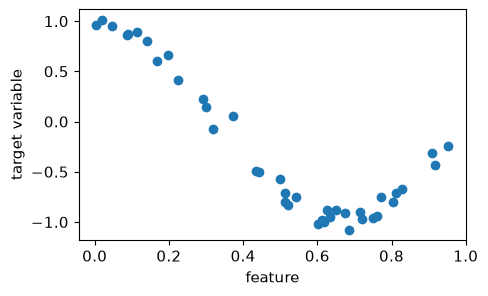

In [1]:
# load packages 
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures
import matplotlib
matplotlib.rcParams.update({'font.size': 11})

df = pd.read_csv('../data/regularization_example.csv')
X_ori = df['x0'].values.reshape(-1, 1)
y = df['y'].values
print(np.shape(X_ori))
print(np.shape(y))

# visualize the data
plt.figure(figsize=(5,3))
plt.scatter(X_ori,y)
plt.xlabel('feature')
plt.ylabel('target variable')
plt.show()

In [2]:
# lets generate more features because a linear model will obviously be insufficient to fit the data well
pf = PolynomialFeatures(degree = 40,include_bias=False)
X = pf.fit_transform(X_ori) # ori means original dataset
print(np.shape(X))
print(pf.get_feature_names_out())

(40, 40)
['x0' 'x0^2' 'x0^3' 'x0^4' 'x0^5' 'x0^6' 'x0^7' 'x0^8' 'x0^9' 'x0^10'
 'x0^11' 'x0^12' 'x0^13' 'x0^14' 'x0^15' 'x0^16' 'x0^17' 'x0^18' 'x0^19'
 'x0^20' 'x0^21' 'x0^22' 'x0^23' 'x0^24' 'x0^25' 'x0^26' 'x0^27' 'x0^28'
 'x0^29' 'x0^30' 'x0^31' 'x0^32' 'x0^33' 'x0^34' 'x0^35' 'x0^36' 'x0^37'
 'x0^38' 'x0^39' 'x0^40']


## We split data into train and validation!

In [3]:
from sklearn.model_selection import train_test_split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=13)
print(np.shape(X_train),np.shape(y_train))
print(np.shape(X_val),np.shape(y_val))

(32, 40) (32,)
(8, 40) (8,)


## Let's train and validate some linear regression models

### Use the first feature only

intercept: 0.8440472807169648
w: [-2.38454357]
train MSE: 0.13004306062481352
val MSE: 0.21337209711536057


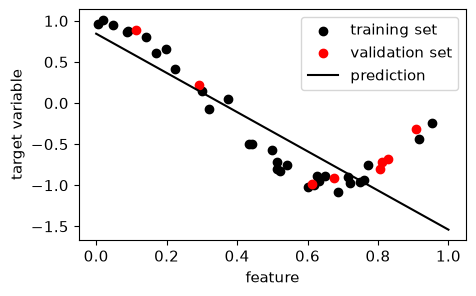

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# let's use only the first feature
linreg = LinearRegression(fit_intercept=True)
linreg.fit(X_train[:,:1], y_train)
print('intercept:',linreg.intercept_)
print('w:',linreg.coef_)

train_MSE = mean_squared_error(y_train,linreg.predict(X_train[:,:1]))
val_MSE = mean_squared_error(y_val,linreg.predict(X_val[:,:1]))
print('train MSE:',train_MSE)
print('val MSE:',val_MSE)


# let's visualuze the model
x_model = np.linspace(0,1,100)
plt.figure(figsize=(5,3))
plt.scatter(X_train[:,0],y_train,color='k',label='training set')
plt.scatter(X_val[:,0],y_val,color='r',label='validation set')
plt.plot(x_model,linreg.predict(x_model.reshape(-1,1)),color='k',label='prediction')
plt.xlabel('feature')
plt.ylabel('target variable')
plt.legend()
plt.show()


### Use all features

intercept: 0.9936225404569743
ws: [  -1.02328771    8.91193934 -153.87037245  487.92285704 -368.9489987
 -459.34514552  168.48841205  578.08334876  452.25076398   14.61727855
 -404.81521634 -607.07835792 -556.49478952 -322.18986653   -9.53670623
  286.46310939  502.41268209  609.62945863  607.66753273  514.60606919
  357.7955338   166.69614062  -31.83305016 -216.08584325 -370.43481522
 -485.1800899  -555.78129243 -581.81355392 -565.87507504 -512.58175445
 -427.71699576 -317.55953117 -188.38435243  -46.11683502  103.88625426
  256.95618131  409.15735825  557.27986363  698.797069    831.80216828]
train MSE: 0.005031610852764185
val MSE: 1.3333753008440423


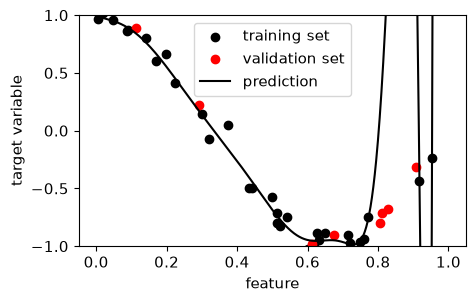

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# use all features
linreg = LinearRegression(fit_intercept=True)
linreg.fit(X_train, y_train)
print('intercept:',linreg.intercept_)
print('ws:',linreg.coef_)

train_MSE = mean_squared_error(y_train,linreg.predict(X_train))
val_MSE = mean_squared_error(y_val,linreg.predict(X_val))
print('train MSE:',train_MSE)
print('val MSE:',val_MSE)


# let's visualuze the model
x_model = np.linspace(0,1,1000)
plt.figure(figsize=(5,3))
plt.scatter(X_train[:,0],y_train,color='k',label='training set')
plt.scatter(X_val[:,0],y_val,color='r',label='validation set')
plt.plot(x_model,linreg.predict(pf.transform(x_model.reshape(-1,1))),color='k',label='prediction')
plt.ylim([-1,1])
plt.xlabel('feature')
plt.ylabel('target variable')
plt.legend()
plt.show()


## What to do?
- the model is visibly performs poorly when only the original feature is used
- the model performs very good on the training set but poorly on the validation set when all features are used
    - the ws are huge!

## Regulazation solves this problem!


## <font color='LIGHTGRAY'>Regularization</font>

<font color='LIGHTGRAY'>By the end of this lecture, you will be able to</font>
- <font color='LIGHTGRAY'>Describe why regularization is important and what are the two types of regularization</font>
- **Describe how regularized linear regression works**
- <font color='LIGHTGRAY'>Describe how regularized logistic regression works</font>


## Regularization to the rescue!
- let's change the loss function and add a <font color='RED'>penalty term</font> for large ws
- **Lasso regression**: regularize using the l1 norm of w:
   
<center>$L(w) = \frac{1}{m}\sum_{i=1}^{m}[(w_0 + \sum_{j=1}^{d} w_j  x_{ij}- y_i)^2] + \color{red}{ \alpha \sum_{j=0}^{d}|w_j|}$</center>   
   
- **Ridge regression**: regularize using the square of the l2 norm of w:
   
<center>$L(w) = \frac{1}{m}\sum_{i=1}^{m}[(w_0 + \sum_{j=1}^{d} w_j  x_{ij}- y_i)^2] + \color{red}{\alpha \sum_{j=0}^{d} w_j^2}$</center>

- $\alpha$ is the regularization parameter (positive number), it describes how much we penalize large ws

- With the loss function changed, the derivatives in gradient descent need to be updated too!

## Feature selection with Lasso regularization
- Least Absolute Shrinkage and Selection Operator
- loss = MSE + $\alpha$ * l1 norm of $w$
<center>$L(w) = \frac{1}{m}\sum_{i=1}^{m}[(w_0 + \sum_{j=1}^{d} w_j  x_{ij}- y_i)^2] + \color{red}{ \alpha \sum_{j=0}^{d}|w_j|}$</center>  
- ideal for feature selection
- as $\alpha$ increases, more and more feature weights are reduced to 0.

In [12]:
from  sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error

alpha = np.logspace(-7,0,29)
print(alpha)
#stop
ws = []
models = []
train_MSE = np.zeros(len(alpha))
val_MSE = np.zeros(len(alpha))

# do the fit
for i in range(len(alpha)):
    # load the linear regression model
    lin_reg = Lasso(alpha=alpha[i], max_iter=10000000)
    lin_reg.fit(X_train, y_train)
    ws.append(lin_reg.coef_)
    models.append(lin_reg)
    train_MSE[i] = mean_squared_error(y_train,lin_reg.predict(X_train))
    val_MSE[i] = mean_squared_error(y_val,lin_reg.predict(X_val))

[1.00000000e-07 1.77827941e-07 3.16227766e-07 5.62341325e-07
 1.00000000e-06 1.77827941e-06 3.16227766e-06 5.62341325e-06
 1.00000000e-05 1.77827941e-05 3.16227766e-05 5.62341325e-05
 1.00000000e-04 1.77827941e-04 3.16227766e-04 5.62341325e-04
 1.00000000e-03 1.77827941e-03 3.16227766e-03 5.62341325e-03
 1.00000000e-02 1.77827941e-02 3.16227766e-02 5.62341325e-02
 1.00000000e-01 1.77827941e-01 3.16227766e-01 5.62341325e-01
 1.00000000e+00]


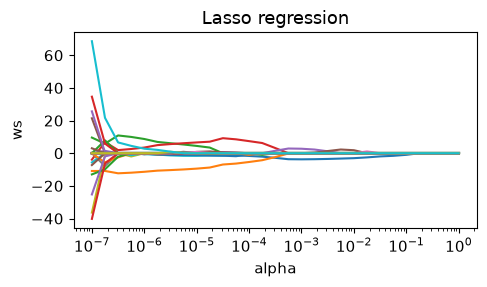

In [13]:
plt.figure(figsize=(5,3))
plt.plot(alpha, ws)
plt.semilogx()
plt.xlabel('alpha')
plt.ylabel('ws')
plt.title('Lasso regression')
plt.tight_layout()
plt.savefig('../figures/lasso_coefs.png',dpi=300)
plt.show()

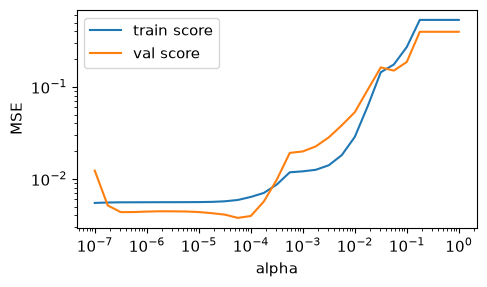

In [14]:
plt.figure(figsize=(5,3))
plt.plot(alpha,train_MSE,label='train score')
plt.plot(alpha,val_MSE,label='val score')
plt.semilogy()
plt.semilogx()
plt.xlabel('alpha')
plt.ylabel('MSE')
plt.legend()
plt.tight_layout()
plt.savefig('../figures/train_val_MSE_lasso.png',dpi=300)
plt.show()

## Bias vs variance
- Bias: the model performs poorly on both the train and validation sets
    - high alpha in our example
- the model performs very well on the training set but it performs poorly on the validation set
    - low alpha in our example
    - lowering the alpha further would improve the train score but the validation score would increase
    - we don't do it because of convergence issues

# The bias-variance trade off
- the curve of the validation score as a function of a hyper-parameter usually has a U shape if evaluation metric needs to be minimized, or an inverted U if the metric needs to be maximized
- choose the hyper-parameter value that gives you the best validation score

##  Quiz
Which alpha value gives the best validation score? Visualize the corresponding model! 

In [22]:
# your code here
print('best alpha:', np.min(val_MSE))
print('the index or argument of the best alpha:', np.argmin(val_MSE))
nest_model = model[11]

###


# let's visualuze the model
x_model = np.linspace(0,1,1000)
plt.figure(figsize=(5,3))
plt.scatter(X_train[:,0],y_train,color='k',label='training set')
plt.scatter(X_val[:,0],y_val,color='r',label='validation set')
plt.plot(x_model, best_model.predict(pf.transform(x_model.reshape(-1,1))),color='k',label='prediction')
plt.ylim([-1,1])
plt.xlabel('feature')
plt.ylabel('target variable')
plt.legend()
plt.show()

best alpha: 0.004645626425770935
the index or argument of the best alpha: 0


NameError: name 'model' is not defined

## The bias-variance tradeoff with Ridge regularization
- loss = MSE + $\alpha$ * (l2 norm of $w$)^2
<center>$L(w) = \frac{1}{m}\sum_{i=1}^{m}[(w_0 + \sum_{j=1}^{d} w_j  x_{ij}- y_i)^2] + \color{red}{\alpha \sum_{j=0}^{d} w_j^2}$</center>

- as $\alpha$ approaches 0, we reproduce the linear regression weights
- small $\alpha$ creates high variance
- large $\alpha$ creates high bias

In [24]:
from  sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

alpha = np.logspace(-10,0,51)

# arrays to save train and test MSE scores
train_MSE = np.zeros(len(alpha))
val_MSE = np.zeros(len(alpha))

ws = []
models = []
# do the fit
for i in range(len(alpha)):
    # load the linear regression model
    lin_reg = Ridge(alpha=alpha[i])
    lin_reg.fit(X_train, y_train)
    models.append(lin_reg)
    ws.append(lin_reg.coef_)
    # train and test scores
    train_MSE[i] = mean_squared_error(y_train,lin_reg.predict(X_train))
    val_MSE[i] = mean_squared_error(y_val,lin_reg.predict(X_val))

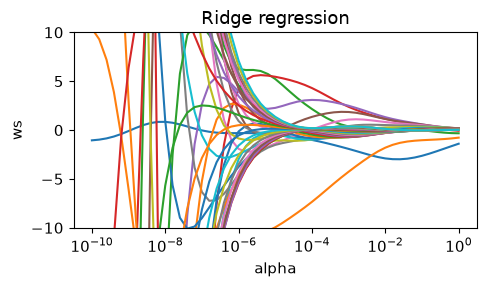

In [16]:
plt.figure(figsize=(5,3))
plt.plot(alpha, ws) 
plt.semilogx()
plt.ylim([-1e1,1e1])
plt.xlabel('alpha')
plt.ylabel('ws')
plt.title('Ridge regression')
plt.tight_layout()
plt.savefig('../figures/ridge_coefs.png',dpi=300)
plt.show()

In [ ]:
plt.figure(figsize=(5,3))
plt.plot(alpha,train_MSE,label='train score')
plt.plot(alpha,val_MSE,label='val score')
plt.semilogy()
plt.semilogx()
plt.xlabel('alpha')
plt.ylabel('MSE loss function')
plt.legend()
plt.tight_layout()
plt.savefig('../figures/train_val_MSE_ridge.png',dpi=300)
plt.show()

## Quiz
Which $\alpha$ gives us the best tradeoff between bias and variance?

In [29]:
# your code here:
indx =np.argmin(val_MSE)
print('best alpha:', alpha[index])
best_model = models[indx]




best alpha: 6.309573444801943e-06


## <font color='LIGHTGRAY'>Regularization</font>

<font color='LIGHTGRAY'>By the end of this lecture, you will be able to</font>
- <font color='LIGHTGRAY'>Describe why regularization is important and what are the two types of regularization</font>
- <font color='LIGHTGRAY'>Describe how regularized linear regression works</font>
- **Describe how regularized logistic regression works**





## Logistic regression
- Recap: the logloss metric is the loss function

<center>$L(w) = - \frac{1}{m}\sum_{i=1}^{m} [y_i\ln(y_i') + (1-y_i)\ln(1-y_i')]$ </center>
<center>$L(w) =  - \frac{1}{m}\sum_{i=1}^{m} [y_i\ln(\frac{1}{1+e^{-w_0 + \sum_{j=1}^{d} w_j  x_{ij}}}) + (1-y_i)\ln(1-\frac{1}{1+e^{-w_0 + \sum_{j=1}^{d} w_j  x_{ij}}})]$</center>

   - the logloss metric with l1 regularization

<center>$L(w) = - \frac{1}{m}\sum_{i=1}^{m} [y_i\ln(y_i') + (1-y_i)\ln(1-y_i'))] + \color{red}{ \alpha \sum_{j=0}^{d}|w_j|}$</center>

   - the logloss metric with l2 regularization

<center>$L(w) = - \frac{1}{m}\sum_{i=1}^{m} [y_i\ln(y_i') + (1-y_i)\ln(1-y_i'))] + \color{red}{\alpha \sum_{j=0}^{d} w_j^2}$</center>

## Logistic regression in sklearn

In [30]:
from sklearn.linear_model import LogisticRegression

log_reg_l1 = LogisticRegression(penalty='l1', C = 1/alpha) # C is the inverse of the regularization strength
log_reg_l2 = LogisticRegression(penalty='l2', C = 1/alpha)
# fit, predict, predict_proba are available 
# log_reg.coef_ returns the w values


In [31]:
help(LogisticRegression)

Help on class LogisticRegression in module sklearn.linear_model._logistic:

class LogisticRegression(sklearn.callback._callback_support.CallbackSupportMixin, sklearn.linear_model._base.LinearClassifierMixin, sklearn.linear_model._base.SparseCoefMixin, sklearn.base.BaseEstimator)
 |  LogisticRegression(
 |      penalty='deprecated',
 |      *,
 |      C=1.0,
 |      l1_ratio=0.0,
 |      dual=False,
 |      tol=0.0001,
 |      fit_intercept=True,
 |      intercept_scaling=1,
 |      class_weight=None,
 |      random_state=None,
 |      solver='lbfgs',
 |      max_iter=100,
 |      verbose=0,
 |      warm_start=False,
 |      n_jobs=None
 |  )
 |
 |  Logistic Regression (aka logit, MaxEnt) classifier.
 |
 |  This class implements regularized logistic regression using a set of available
 |  solvers. **Note that regularization is applied by default**. It can handle both
 |  dense and sparse input `X`. Use C-ordered arrays or CSR matrices containing 64-bit
 |  floats for optimal performance

# Mudcard